# RouteWise Incident Desk

Restore Himani's saved Qwen3 LoRA adapter and try the first working desk.
**No repeat training and no Google Drive mount are needed.**

1. Choose **Runtime → Change runtime type → T4 GPU**.
2. Run cells **1–5** below in order. Cell 2 asks for the original 127.4 MB backup ZIP.
3. Stop after the desk appears. The development evaluation at the bottom is optional.

This is an experimental demo. Automatic routing is off by default; the slider values
have not been selected on independent calibration data. Replay examples are synthetic.
The original notebook and adapter backup remain unchanged.


In [1]:
#@title 1. Install inference and notebook dependencies
import subprocess, sys
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "transformers==5.8.0", "peft==0.18.1", "accelerate==1.11.0",
    "safetensors>=0.4.3", "scikit-learn>=1.5,<2",
    "pandas>=2.2,<3", "ipywidgets>=8.1,<9", "matplotlib>=3.9,<4",
])
import torch
assert torch.cuda.is_available(), "Select a T4 GPU runtime and rerun."
x = torch.randn(32, 32, device="cuda")
_ = x @ x
torch.cuda.synchronize()
del x, _
print("GPU computation passed:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
print("Continue to cell 2. If Colab requests a session restart, restart and rerun this cell first.")


GPU computation passed: Tesla T4
PyTorch: 2.14.1+cu130
Continue to cell 2. If Colab requests a session restart, restart and rerun this cell first.


In [2]:
#@title 2. Upload your original backup ZIP
from google.colab import files
from pathlib import Path
import hashlib, json, zipfile, sys
print("Select RouteWise_backup_20261107_065144_745885.zip (the duplicate (1) is also accepted).")
uploaded = files.upload()
archives = [Path(name) for name in uploaded if name.lower().endswith('.zip')]
assert len(archives) == 1, "Upload exactly one backup ZIP."
archive = archives[0]
del uploaded
expected_hash = "19b99c7092b87829509ee57f1f97669374a22128ad5c2857644187255919fdc4"
digest = hashlib.sha256(archive.read_bytes()).hexdigest()
assert digest == expected_hash, "This differs from the verified original backup. Stop and check the file."
BACKUP_DIR = Path('/content/routewise_restored')
BACKUP_DIR.mkdir(exist_ok=True)
with zipfile.ZipFile(archive) as zipped:
    assert zipped.testzip() is None, "ZIP integrity check failed."
    for item in zipped.infolist():
        # Intermediate optimizer checkpoints are not needed for inference.
        if item.filename.startswith('adapter/checkpoint-'):
            continue
        if item.filename.endswith(('.pt', '.bin')):
            continue
        target = (BACKUP_DIR / item.filename).resolve()
        assert target.is_relative_to(BACKUP_DIR.resolve()), "Unsafe archive path."
        zipped.extract(item, BACKUP_DIR)
ADAPTER_DIR = BACKUP_DIR / 'adapter'
assert (ADAPTER_DIR / 'adapter_model.safetensors').exists()
original_metrics = json.loads((BACKUP_DIR / 'metrics.json').read_text())
print('Backup restored and fingerprint verified.')
print('Original measured accuracy:', f"{original_metrics['finetuned_accuracy']:.1%}")


Select RouteWise_backup_20261107_065144_745885.zip (the duplicate (1) is also accepted).


Saving RouteWise_backup_20261107_065144_745885.zip to RouteWise_backup_20261107_065144_745885.zip
Backup restored and fingerprint verified.
Original measured accuracy: 70.1%


In [3]:
#@title Install the included RouteWise source files (no extra upload needed)
from pathlib import Path
import json, sys
package_files = {'routewise/__init__.py': '"""RouteWise: inspectable ticket routing and suspected-incident replay."""\n', 'routewise/core.py': '"""Pure Python routing policy, review records, and lexical incident grouping.\n\nNo model calls, network access, or simulated model scores live in this module.\n"""\nfrom collections import Counter\nfrom dataclasses import dataclass, field\nfrom datetime import datetime, timedelta, timezone\nimport math\nimport re\nfrom typing import Mapping\n\nLABELS = (\n    "Support general", "Fileservice", "O365", "EOL", "Software",\n    "Active Directory", "Computer-Services",\n)\nSYSTEM_PROMPT = (\n    "You are an IT helpdesk ticket routing assistant. "\n    "Given a support ticket, respond with exactly one of the following categories: "\n    "Support general, Fileservice, O365, EOL, Software, Active Directory, Computer-Services."\n)\n\n\ndef normalize_scores(log_scores: Mapping[str, float], temperature: float = 1.0) -> dict:\n    if set(log_scores) != set(LABELS):\n        raise ValueError("Scores must contain each of the seven labels exactly once.")\n    if not math.isfinite(temperature) or temperature <= 0:\n        raise ValueError("Temperature must be finite and positive.")\n    values = {k: float(v) for k, v in log_scores.items()}\n    if not all(math.isfinite(v) for v in values.values()):\n        raise ValueError("Non-finite model score; send this ticket for review.")\n    top = max(values.values())\n    weights = {k: math.exp((v - top) / temperature) for k, v in values.items()}\n    total = sum(weights.values())\n    return {k: v / total for k, v in weights.items()}\n\n\ndef validate_scores(scores: Mapping[str, float]) -> None:\n    if set(scores) != set(LABELS):\n        raise ValueError("Missing or unknown routing label.")\n    if not all(math.isfinite(v) and 0 <= v <= 1 for v in scores.values()):\n        raise ValueError("Invalid routing score.")\n    if not math.isclose(sum(scores.values()), 1, abs_tol=1e-5):\n        raise ValueError("Routing scores must sum to one.")\n\n\n@dataclass(frozen=True)\nclass Policy:\n    threshold: float = 0.80\n    min_margin: float = 0.20\n    auto_enabled: bool = False\n\n    def __post_init__(self):\n        if not all(math.isfinite(v) and 0 <= v <= 1\n                   for v in (self.threshold, self.min_margin)):\n            raise ValueError("Threshold and margin must be between zero and one.")\n\n    def decide(self, scores: Mapping[str, float]) -> dict:\n        validate_scores(scores)\n        ranked = sorted(scores.items(), key=lambda x: x[1], reverse=True)\n        label, score = ranked[0]\n        margin = score - ranked[1][1]\n        automatic = self.auto_enabled and score >= self.threshold and margin >= self.min_margin\n        if not self.auto_enabled:\n            reason = "Automatic routing is disabled until you enable the experimental policy."\n        elif score < self.threshold:\n            reason = "Top candidate score is below the review threshold."\n        elif margin < self.min_margin:\n            reason = "The two leading queues are too close."\n        else:\n            reason = "Meets the experimental score and margin thresholds."\n        return {\n            "predicted_queue": label, "top_score": score, "margin": margin,\n            "status": "automatic" if automatic else "needs_review", "reason": reason,\n            "policy": {"threshold": self.threshold, "min_margin": self.min_margin,\n                       "auto_enabled": self.auto_enabled, "validated": False},\n        }\n\n\ndef policy_metrics(records: list[dict], policy: Policy) -> dict:\n    if not records:\n        raise ValueError("No scored examples supplied.")\n    accepted = []\n    for row in records:\n        if row["truth"] not in LABELS:\n            raise ValueError("Evaluation truth must be a routing label.")\n        decision = policy.decide(row["scores"])\n        if decision["status"] == "automatic":\n            accepted.append(decision["predicted_queue"] == row["truth"])\n    n = len(accepted)\n    return {\n        "total": len(records), "automated": n, "review": len(records) - n,\n        "coverage": n / len(records),\n        "automatic_accuracy": sum(accepted) / n if n else None,\n        "automatic_errors": n - sum(accepted),\n    }\n\n\n@dataclass\nclass Desk:\n    tickets: list = field(default_factory=list)\n    reviews: list = field(default_factory=list)\n\n    def add(self, text: str, scores: dict, policy: Policy, timestamp=None, source="manual"):\n        if not text.strip():\n            raise ValueError("Enter a ticket first.")\n        timestamp = timestamp or datetime.now(timezone.utc)\n        if timestamp.tzinfo is None:\n            raise ValueError("Ticket timestamps need a timezone.")\n        decision = policy.decide(scores)\n        record = {\n            "id": f"T{len(self.tickets) + 1:04d}", "text": text,\n            "timestamp": timestamp.isoformat(), "source": source,\n            "scores": dict(scores), **decision,\n            "human_queue": None,\n        }\n        self.tickets.append(record)\n        return record\n\n    def review(self, ticket_id: str, queue: str):\n        if queue not in LABELS:\n            raise ValueError("Choose a valid queue.")\n        ticket = next((x for x in self.tickets if x["id"] == ticket_id), None)\n        if ticket is None:\n            raise ValueError("Ticket not found.")\n        previous = ticket["human_queue"]\n        ticket["human_queue"] = queue\n        ticket["status"] = "reviewed"\n        self.reviews.append({\n            "ticket_id": ticket_id, "queue": queue, "previous_human_queue": previous,\n            "model_queue": ticket["predicted_queue"],\n            "timestamp": datetime.now(timezone.utc).isoformat(),\n        })\n        return ticket\n\n\n_STOPWORDS = set("i my me we our the a an to of and is are it in on for with since please can cannot not has have this all".split())\n_ALIASES = {\n    "outlook": "email", "mailbox": "email", "mailboxes": "email", "emails": "email",\n    "mail": "email", "messages": "email", "message": "email",\n    "sending": "send", "sent": "send", "sends": "send",\n    "failing": "failure", "failed": "failure", "fails": "failure",\n    "stopped": "failure", "broken": "failure", "down": "failure",\n}\n\n\ndef ticket_terms(text: str) -> Counter:\n    words = re.findall(r"[a-z0-9]+", text.lower())\n    return Counter(_ALIASES.get(w, w) for w in words if w not in _STOPWORDS)\n\n\ndef similarity(a: Counter, b: Counter) -> float:\n    denominator = math.sqrt(sum(v*v for v in a.values()) * sum(v*v for v in b.values()))\n    return sum(v * b.get(k, 0) for k, v in a.items()) / denominator if denominator else 0.0\n\n\ndef suspected_incidents(tickets: list[dict], now=None, window_minutes=10,\n                        min_tickets=3, similarity_threshold=0.55) -> list[dict]:\n    """Complete-link grouping avoids merging dissimilar endpoints through a bridge.\n\n    Lexical similarity with documented email aliases; not root-cause diagnosis.\n    Each distinct ticket counts once. Synthetic reporters do not prove real impact.\n    """\n    if window_minutes <= 0 or min_tickets < 2 or not 0 < similarity_threshold <= 1:\n        raise ValueError("Invalid incident grouping settings.")\n    if not tickets:\n        return []\n    times = [datetime.fromisoformat(x["timestamp"]) for x in tickets]\n    if any(x.tzinfo is None for x in times):\n        raise ValueError("Incident timestamps need a timezone.")\n    now = now or max(times)\n    if now.tzinfo is None:\n        raise ValueError("Current time needs a timezone.")\n    recent = {}\n    for ticket, time in zip(tickets, times):\n        if now - timedelta(minutes=window_minutes) <= time <= now:\n            recent[ticket["id"]] = ticket\n    groups = []\n    for ticket in sorted(recent.values(), key=lambda x: (x["timestamp"], x["id"])):\n        terms = ticket_terms(ticket["text"])\n        match = next((g for g in groups if all(\n            similarity(terms, ticket_terms(other["text"])) >= similarity_threshold\n            for other in g)), None)\n        if match is None:\n            groups.append([ticket])\n        else:\n            match.append(ticket)\n    return [{\n        "title": "Suspected shared incident", "ticket_ids": [x["id"] for x in group],\n        "count": len(group), "example": group[0]["text"],\n        "method": "Lexical similarity with email aliases; complete-link grouping",\n        "confirmed": False,\n    } for group in groups if len(group) >= min_tickets]\n', 'routewise/demo.py': '"""A notebook-native desk. No public server or external ticket integrations."""\nfrom datetime import datetime, timedelta, timezone\nfrom html import escape\nfrom pathlib import Path\nimport json\nimport ipywidgets as w\nfrom IPython.display import display, HTML, clear_output\nfrom .core import Desk, Policy, LABELS, suspected_incidents\n\nSCENARIOS = [\n    ("Please install the approved Adobe Acrobat application on my laptop.", "Software"),\n    ("I cannot access the shared folder through Teams. Please investigate.", None),\n    ("Outlook email sending failed for our team this morning.", "O365"),\n    ("Our team email sending failed in Outlook this morning.", "O365"),\n    ("Outlook email sending has failed again for our team this morning.", "O365"),\n    ("Please decommission the retired test server and remove it from monitoring.", "EOL"),\n    ("Please create an Active Directory account for the new employee.", "Active Directory"),\n    ("The office printer has a persistent paper jam and needs repair.", "Computer-Services"),\n]\n\n\ndef launch_desk(router):\n    desk = Desk()\n    output = w.Output()\n    text = w.Textarea(placeholder="Describe the support request…", layout=w.Layout(width="100%", height="90px"))\n    threshold = w.FloatSlider(value=.80, min=.15, max=.99, step=.01,\n                              description="Score cutoff", style={"description_width": "initial"})\n    margin = w.FloatSlider(value=.20, min=0, max=.8, step=.01,\n                           description="Top-two gap", style={"description_width": "initial"})\n    automatic = w.Checkbox(value=False, description="Enable experimental automatic routing")\n    route = w.Button(description="Route ticket", button_style="primary")\n    replay = w.Button(description="Replay 8 synthetic tickets")\n    refresh = w.Button(description="Refresh desk")\n    export = w.Button(description="Download desk records")\n    ticket_select = w.Dropdown(options=[], description="Ticket")\n    queue_select = w.Dropdown(options=LABELS, description="Human queue")\n    review = w.Button(description="Save human decision")\n    notice = w.HTML()\n\n    def policy():\n        return Policy(threshold.value, margin.value, automatic.value)\n\n    def table(headers, rows):\n        return "<table style=\'width:100%;border-collapse:collapse\'>" + "<tr>" + "".join(\n            f"<th style=\'text-align:left;padding:8px;border-bottom:1px solid #aaa\'>{escape(str(h))}</th>"\n            for h in headers) + "</tr>" + "".join("<tr>" + "".join(\n                f"<td style=\'padding:8px;border-bottom:1px solid #ddd\'>{escape(str(v))}</td>"\n                for v in row) + "</tr>" for row in rows) + "</table>"\n\n    def render():\n        ticket_select.options = [(f"{r[\'id\']} · {r[\'status\']}", r[\'id\']) for r in desk.tickets]\n        with output:\n            clear_output(wait=True)\n            auto = sum(r["status"] == "automatic" for r in desk.tickets)\n            pending = sum(r["status"] == "needs_review" for r in desk.tickets)\n            display(HTML(f"<h3>Ticket desk</h3><p>{len(desk.tickets)} tickets · {auto} automatic · "\n                         f"{pending} awaiting review · {len(desk.reviews)} human decisions</p>"))\n            display(HTML("<p>Scores are relative preferences across seven labels, not validated probabilities "\n                         "of correctness. Threshold changes affect new decisions only.</p>"))\n            if desk.tickets:\n                display(HTML(table(["ID", "Ticket", "Suggested queue", "Status", "Human queue", "Source"], [\n                    [r[\'id\'], r[\'text\'], r[\'predicted_queue\'] or \'Inference failed\', r[\'status\'],\n                     r[\'human_queue\'] or \'—\', r[\'source\']] for r in desk.tickets])))\n                latest = desk.tickets[-1]\n                if latest[\'scores\']:\n                    display(HTML("<h3>Latest ticket candidate scores</h3>" + table(\n                        ["Queue", "Relative score"],\n                        [(k, f"{v:.3f}") for k, v in sorted(latest[\'scores\'].items(), key=lambda x:x[1], reverse=True)])))\n                display(HTML(f"<p>{escape(latest[\'reason\'])}</p>"))\n                incidents = suspected_incidents(desk.tickets)\n                display(HTML("<h3>Incident Radar</h3><p>Lexical grouping over a 10-minute window; "\n                             "three reports required. Groups are suspected, not confirmed outages.</p>"))\n                for group in incidents:\n                    display(HTML(f"<p><b>{escape(group[\'title\'])}</b>: {group[\'count\']} reports · "\n                                 f"{escape(\', \'.join(group[\'ticket_ids\']))}<br>{escape(group[\'example\'])}</p>"))\n                if not incidents:\n                    display(HTML("<p>No group currently meets the incident settings.</p>"))\n\n    def add(ticket, timestamp=None, source="manual"):\n        try:\n            result = router.score(ticket)\n            record = desk.add(ticket, result[\'scores\'], policy(), timestamp, source)\n            record.update({k: result[k] for k in [\'log_scores\', \'latency_ms\', \'score_method\', \'calibrated\']})\n        except Exception as error:\n            # Preserve inference failures as review items, with no invented label or score.\n            record = {\n                \'id\': f\'T{len(desk.tickets)+1:04d}\', \'text\': ticket,\n                \'timestamp\': (timestamp or datetime.now(timezone.utc)).isoformat(),\n                \'source\': source, \'scores\': {}, \'predicted_queue\': None,\n                \'human_queue\': None, \'status\': \'needs_review\',\n                \'reason\': f\'Inference failed: {type(error).__name__}: {error}\',\n            }\n            desk.tickets.append(record)\n        return record\n\n    def on_route(_):\n        if not text.value.strip():\n            notice.value = "Enter a ticket first."\n            return\n        route.disabled = replay.disabled = True\n        notice.value = "Scoring all seven complete labels…"\n        try:\n            add(text.value)\n            render()\n            notice.value = "Ticket processed."\n        finally:\n            route.disabled = replay.disabled = False\n\n    def on_replay(_):\n        route.disabled = replay.disabled = True\n        start = datetime.now(timezone.utc) - timedelta(minutes=4)\n        try:\n            for i, (ticket, expected) in enumerate(SCENARIOS):\n                notice.value = f"Scoring synthetic ticket {i+1}/{len(SCENARIOS)}…"\n                record = add(ticket, start + timedelta(seconds=30*i), \'synthetic_replay\')\n                record[\'illustrative_expected_queue\'] = expected\n                render()\n            notice.value = "Synthetic replay complete. These examples are not a benchmark."\n        finally:\n            route.disabled = replay.disabled = False\n\n    def on_review(_):\n        if ticket_select.value:\n            desk.review(ticket_select.value, queue_select.value)\n            render()\n            notice.value = "Human decision saved. Model weights have not changed."\n\n    def on_export(_):\n        path = Path(\'/content/routewise_desk_records.json\')\n        path.write_text(json.dumps({\n            \'tickets\': desk.tickets, \'reviews\': desk.reviews,\n            \'notice\': \'Experimental policy; synthetic replay is not benchmark evidence.\',\n        }, indent=2), encoding=\'utf-8\')\n        from google.colab import files\n        files.download(str(path))\n\n    route.on_click(on_route)\n    replay.on_click(on_replay)\n    refresh.on_click(lambda _: render())\n    review.on_click(on_review)\n    export.on_click(on_export)\n    display(w.VBox([\n        w.HTML("<h2>RouteWise Incident Desk</h2><p>Your restored Qwen LoRA model · "\n               "experimental review policy · notebook session storage</p>"),\n        text, w.HBox([threshold, margin]), automatic,\n        w.HBox([route, replay, refresh, export]), notice,\n        w.HBox([ticket_select, queue_select, review]), output,\n    ]))\n    render()\n    return desk\n', 'routewise/inference.py': '"""GPU inference, imported only after the Colab dependency cell has run."""\nfrom pathlib import Path\nfrom time import perf_counter\nimport math\nimport torch\nfrom transformers import AutoModelForCausalLM, AutoTokenizer\nfrom peft import PeftModel\nfrom .core import LABELS, SYSTEM_PROMPT, normalize_scores\n\nBASE_MODEL = "Qwen/Qwen3-1.7B-Base"\n# Recorded in the successful original training log; do not silently change weights.\nBASE_REVISION = "ea980cb0a6c2ae4b936e82123acc929f1cec04c1"\n\n\nclass Router:\n    def __init__(self, model, tokenizer, max_tokens=2048):\n        self.model, self.tokenizer = model.eval(), tokenizer\n        self.max_tokens = max_tokens\n        if not tokenizer.chat_template:\n            raise ValueError("The saved adapter tokenizer must contain its chat template.")\n        if tokenizer.eos_token_id is None:\n            raise ValueError("Saved tokenizer has no EOS token.")\n        self.candidates = {\n            label: tokenizer.encode(label, add_special_tokens=False) + [tokenizer.eos_token_id]\n            for label in LABELS\n        }\n\n    @classmethod\n    def restore(cls, adapter_dir):\n        adapter_dir = Path(adapter_dir)\n        if not torch.cuda.is_available():\n            raise RuntimeError("Choose a T4 GPU runtime before loading the model.")\n        tokenizer = AutoTokenizer.from_pretrained(str(adapter_dir), local_files_only=True)\n        base = AutoModelForCausalLM.from_pretrained(\n            BASE_MODEL, revision=BASE_REVISION,\n            torch_dtype=torch.float16, device_map={"": 0},\n            attn_implementation="sdpa",\n        )\n        model = PeftModel.from_pretrained(base, str(adapter_dir), is_trainable=False)\n        # Training replaced EOS with im_end. Keep restored generation consistent.\n        model.config.eos_token_id = tokenizer.eos_token_id\n        model.config.pad_token_id = tokenizer.pad_token_id\n        model.generation_config.eos_token_id = tokenizer.eos_token_id\n        model.generation_config.pad_token_id = tokenizer.pad_token_id\n        return cls(model, tokenizer)\n\n    def _prompt_ids(self, text):\n        if not isinstance(text, str) or not text.strip():\n            raise ValueError("Ticket must contain text.")\n        if "<|im_start|>" in text or "<|im_end|>" in text:\n            raise ValueError("Ticket contains chat control tokens; send for manual review.")\n        messages = [\n            {"role": "system", "content": SYSTEM_PROMPT},\n            {"role": "user", "content": f"Support Ticket: {text}"},\n        ]\n        # Do not pass enable_thinking=False: that saved Qwen Jinja template adds\n        # an empty think block, whereas qwen3_nothink training used a plain prefix.\n        prompt = self.tokenizer.apply_chat_template(\n            messages, tokenize=False, add_generation_prompt=True,\n        )\n        if not prompt.endswith("<|im_start|>assistant\\n"):\n            raise ValueError("Unexpected generation prefix; check the saved tokenizer template.")\n        ids = self.tokenizer.encode(prompt, add_special_tokens=False)\n        if len(ids) + max(map(len, self.candidates.values())) > self.max_tokens:\n            raise ValueError("Ticket exceeds the training token limit; manual review required.")\n        return ids\n\n    @torch.inference_mode()\n    def score(self, text, temperature=1.0):\n        prompt = self._prompt_ids(text)\n        torch.cuda.synchronize()\n        start = perf_counter()\n        raw = {}\n        for label, completion in self.candidates.items():\n            ids = torch.tensor([prompt + completion], device=self.model.device)\n            mask = torch.ones_like(ids)\n            # Retain only positions that predict the complete label and EOS.\n            # Sequential candidates bound peak GPU memory for the large vocabulary.\n            logits = self.model(\n                input_ids=ids, attention_mask=mask, use_cache=False,\n                logits_to_keep=len(completion) + 1,\n            ).logits[0, :-1, :].float()\n            targets = torch.tensor(completion, device=logits.device)\n            token_scores = logits.log_softmax(-1).gather(-1, targets[:, None]).squeeze(-1)\n            raw[label] = token_scores.sum().item()\n            del logits, token_scores\n        torch.cuda.synchronize()\n        scores = normalize_scores(raw, temperature=temperature)\n        return {\n            "prediction": max(scores, key=scores.get), "scores": scores,\n            "log_scores": raw, "latency_ms": (perf_counter() - start) * 1000,\n            "score_method": "Sum of complete-label and EOS log likelihoods",\n            "calibrated": False, "temperature": temperature,\n        }\n\n    @torch.inference_mode()\n    def generate_label(self, text):\n        prompt = self._prompt_ids(text)\n        ids = torch.tensor([prompt], device=self.model.device)\n        output = self.model.generate(\n            input_ids=ids, attention_mask=torch.ones_like(ids),\n            max_new_tokens=24, do_sample=False, use_cache=True,\n            eos_token_id=self.tokenizer.eos_token_id,\n            pad_token_id=self.tokenizer.pad_token_id,\n        )\n        generated = self.tokenizer.decode(output[0, len(prompt):], skip_special_tokens=True).strip()\n        # Never silently convert a malformed generation into Support general.\n        return {"raw_output": generated, "valid": generated in LABELS,\n                "prediction": generated if generated in LABELS else None}\n'}
for relative, source in package_files.items():
    target = Path("/content") / relative
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_text(source, encoding="utf-8")
if "/content" not in sys.path: sys.path.insert(0, "/content")
print("RouteWise modules ready.")


RouteWise modules ready.


In [4]:
#@title 3. Load your trained model
from routewise.inference import Router, BASE_MODEL, BASE_REVISION
print('Downloading/loading the original base model, then attaching your saved LoRA adapter…')
router = Router.restore(ADAPTER_DIR)
print('RESTORED:', BASE_MODEL)
print('Base revision:', BASE_REVISION)
print('Saved EOS:', router.tokenizer.eos_token)
print('Ready for the smoke check. No training was performed.')


Downloading/loading the original base model, then attaching your saved LoRA adapter…


config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.44GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

RESTORED: Qwen/Qwen3-1.7B-Base
Base revision: ea980cb0a6c2ae4b936e82123acc929f1cec04c1
Saved EOS: <|im_end|>
Ready for the smoke check. No training was performed.


In [5]:
#@title 4. Check generation and complete-label scoring
import pandas as pd
import json
smoke_cases = [
    ('Please install Adobe Acrobat on my laptop.', 'Software'),
    ('Please create an Active Directory account for a new employee.', 'Active Directory'),
    ('Please retire the old server and remove it from monitoring.', 'EOL'),
    ('Outlook cannot send email from my mailbox.', 'O365'),
    ('Please grant access to the shared network folder.', 'Fileservice'),
    ('The office printer has a paper jam and needs repair.', 'Computer-Services'),
]
smoke_results = []
for ticket, expected in smoke_cases:
    generated = router.generate_label(ticket)
    scored = router.score(ticket)
    smoke_results.append({
        'ticket': ticket, 'illustrative_expected': expected,
        'generated_label': generated['prediction'],
        'raw_generation': generated['raw_output'],
        'valid_generation': generated['valid'],
        'scored_label': scored['prediction'],
        'top_relative_score': max(scored['scores'].values()),
        'scores': scored['scores'], 'latency_ms': scored['latency_ms'],
    })
display(pd.DataFrame(smoke_results).drop(columns=['scores']))
Path('/content/routewise_smoke_results.json').write_text(json.dumps(smoke_results, indent=2))
print('These six illustrative examples are not a validation benchmark.')
print('Different predictions from generation and scoring are possible; keep both results.')
print('If loading failed or every generation is invalid, share the output before continuing.')


,ticket,illustrative_expected,generated_label,raw_generation,valid_generation,scored_label,top_relative_score,latency_ms
0,Please install Adobe Acrobat on my laptop.,Software,None,Software取得以及\n取得以及user\nSupport Ticket: I am h...,False,Software,0.966348,591.385145
1,Please create an Active Directory account for ...,Active Directory,None,Active Directory取得以及\n取得以及user\nSupport Ticket...,False,Active Directory,0.997646,502.432620
2,Please retire the old server and remove it fro...,EOL,None,EOL取得以及\n取得以及\n取得以及\n取得以及\n取得以及\n取得以及\n取得以及\n取...,False,EOL,0.972316,500.088955
3,Outlook cannot send email from my mailbox.,O365,None,O365取得以及\n取得以及user\nSupport Ticket: I cannot s...,False,O365,0.976214,493.541373
4,Please grant access to the shared network folder.,Fileservice,None,Fileservice取得以及\n取得以及\n取得以及\n取得以及\n取得以及\n取得以及\...,False,Fileservice,0.889298,652.159466
5,The office printer has a paper jam and needs r...,Computer-Services,None,Computer-Services席执行\n executing\n executing\n...,False,Computer-Services,0.709643,492.030501


These six illustrative examples are not a validation benchmark.
Different predictions from generation and scoring are possible; keep both results.
If loading failed or every generation is invalid, share the output before continuing.


In [7]:
display(pd.DataFrame(smoke_results)[[
    "illustrative_expected",
    "raw_generation",
    "valid_generation",
    "scored_label",
    "top_relative_score",
]])

,illustrative_expected,raw_generation,valid_generation,scored_label,top_relative_score
0,Software,Software取得以及\n取得以及user\nSupport Ticket: I am h...,False,Software,0.966348
1,Active Directory,Active Directory取得以及\n取得以及user\nSupport Ticket...,False,Active Directory,0.997646
2,EOL,EOL取得以及\n取得以及\n取得以及\n取得以及\n取得以及\n取得以及\n取得以及\n取...,False,EOL,0.972316
3,O365,O365取得以及\n取得以及user\nSupport Ticket: I cannot s...,False,O365,0.976214
4,Fileservice,Fileservice取得以及\n取得以及\n取得以及\n取得以及\n取得以及\n取得以及\...,False,Fileservice,0.889298
5,Computer-Services,Computer-Services席执行\n executing\n executing\n...,False,Computer-Services,0.709643


In [6]:
#@title 5. Open the RouteWise Incident Desk
from routewise.demo import launch_desk
desk = launch_desk(router)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Try the first demo

- Enter a ticket and choose **Route ticket**.
- Automatic routing defaults off. Enable the experimental policy to try score and gap thresholds.
- Choose a ticket and human queue, then save the human decision. Original model predictions stay visible.
- Choose **Replay 8 synthetic tickets**. Routing uses your actual model; incident grouping uses words
  and a few documented email aliases. Similarity is not proof of a shared root cause.
- Download desk records before closing the runtime; session storage is temporary.

**Pause here and share the smoke-check output and a screenshot of the desk.**
Neither a high score nor a successful replay establishes production accuracy.


## Optional development experiment

Run this only after restoration works. It scores all 117 original validation tickets using
the same prompt and candidate-label procedure with the adapter on and off. Allow several minutes.
It does not reproduce the original letter-choice baseline; both measurements are retained separately.

This set has already been inspected, so the sweep is exploratory. Do not choose the best threshold
here and call it independent test performance. A separate calibration/test experiment comes next.


In [8]:
#@title 6. Optional paired development evaluation (117 tickets, two models)
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, classification_report
from routewise.core import LABELS
validation = pd.read_csv(BACKUP_DIR / 'val_split.csv')
development_rows = []
for _, row in tqdm(validation.iterrows(), total=len(validation)):
    tuned = router.score(row['text'])
    with router.model.disable_adapter():
        base = router.score(row['text'])
    development_rows.append({
        'text': row['text'], 'truth': row['label'],
        'prediction': tuned['prediction'], 'scores': tuned['scores'],
        'log_scores': tuned['log_scores'], 'latency_ms': tuned['latency_ms'],
        'base_prediction': base['prediction'], 'base_scores': base['scores'],
        'base_latency_ms': base['latency_ms'],
    })
truth = [r['truth'] for r in development_rows]
dev_metrics = {
    'evaluation_status': 'Exploratory on previously inspected validation examples',
    'base_revision': BASE_REVISION, 'score_method': 'Complete label plus EOS log likelihood',
    'baseline_accuracy': accuracy_score(truth, [r['base_prediction'] for r in development_rows]),
    'tuned_accuracy': accuracy_score(truth, [r['prediction'] for r in development_rows]),
    'tuned_report': classification_report(truth, [r['prediction'] for r in development_rows],
        labels=list(LABELS), target_names=list(LABELS), output_dict=True, zero_division=0),
}
print('Base accuracy, same scoring:', f"{dev_metrics['baseline_accuracy']:.1%}")
print('Tuned accuracy, same scoring:', f"{dev_metrics['tuned_accuracy']:.1%}")
print('Original tuned generation accuracy:', f"{original_metrics['finetuned_accuracy']:.1%}")


  0%|          | 0/117 [00:00<?, ?it/s]

Base accuracy, same scoring: 23.9%
Tuned accuracy, same scoring: 70.1%
Original tuned generation accuracy: 70.1%


,threshold,total,automated,review,coverage,automatic_accuracy,automatic_errors
0,0.20,117,101,16,0.863248,0.772277,23
1,0.30,117,101,16,0.863248,0.772277,23
2,0.40,117,101,16,0.863248,0.772277,23
3,0.50,117,97,20,0.829060,0.762887,23
4,0.60,117,85,32,0.726496,0.788235,18
5,0.70,117,73,44,0.623932,0.821918,13
6,0.80,117,54,63,0.461538,0.851852,8
7,0.90,117,38,79,0.324786,0.921053,3
8,0.95,117,28,89,0.239316,0.928571,2
9,0.99,117,3,114,0.025641,0.666667,1


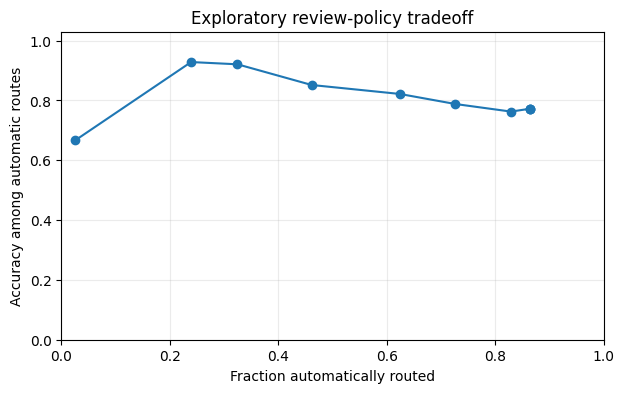

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
#@title 7. Optional coverage experiment and download
from routewise.core import Policy, policy_metrics
import matplotlib.pyplot as plt
import shutil
assert 'development_rows' in globals(), 'Run optional cell 6 first.'
sweep = []
for value in [.2, .3, .4, .5, .6, .7, .8, .9, .95, .99]:
    sweep.append({'threshold':value, **policy_metrics(
        development_rows, Policy(threshold=value, min_margin=.2, auto_enabled=True))})
sweep_df = pd.DataFrame(sweep)
display(sweep_df)
valid = sweep_df.dropna(subset=['automatic_accuracy'])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(valid['coverage'], valid['automatic_accuracy'], 'o-')
ax.set(xlabel='Fraction automatically routed', ylabel='Accuracy among automatic routes',
       title='Exploratory review-policy tradeoff', xlim=(0,1), ylim=(0,1.03))
ax.grid(alpha=.25)
plt.show()
export_dir = Path('/content/routewise_development_results')
export_dir.mkdir(exist_ok=True)
fig.savefig(export_dir / 'exploratory_coverage.png', dpi=150, bbox_inches='tight')
sweep_df.to_csv(export_dir / 'exploratory_thresholds.csv', index=False)
(export_dir / 'scored_tickets.json').write_text(json.dumps(development_rows, indent=2))
(export_dir / 'metrics.json').write_text(json.dumps(dev_metrics, indent=2))
(export_dir / 'smoke_results.json').write_text(json.dumps(smoke_results, indent=2))
(export_dir / 'desk_records.json').write_text(json.dumps(
    {'tickets':desk.tickets, 'reviews':desk.reviews}, indent=2))
files.download(shutil.make_archive(str(export_dir), 'zip', root_dir=export_dir))
